In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *
# import plot_preferences

2025-02-14 16:39:11.405209: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-02-14 16:39:11.462071: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-02-14 16:39:11.462106: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-02-14 16:39:11.463526: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-14 16:39:11.474458: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-02-14 16:39:11.475008: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [ ]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']
# colors = np.array([[0.3 , 0.8 , 0.3 ],
#        [0.3 , 0.8 , 0.55],
#        [0.3 , 0.8 , 0.8 ],
#        [0.3 , 0.55, 0.8 ],
#        [0.3 , 0.3 , 0.8 ]])

colors = np.array([[0.8, 0.3, 0.7],
       [0.8, 0.5, 0.3],
       [0.5, 0.8, 0.3],
       [0.3, 0.8, 0.7],
       [0.3, 0.3, 0.8]])

data = [None]*len(stimuli)
data_dict = [None]*len(stimuli)

for j, stim in enumerate(stimuli):
    load_path = project_folder + f'/analyses/info decay timescale/saved/{stim}/all neurons, high-iter.dat'
    with open(load_path, 'rb') as f:
        data_dict[j] = pickle.load(f)
    data[j] = Namespace(**data_dict[j])

data_shuffle = [None]*len(stimuli)
data_dict_shuffle = [None]*len(stimuli)
for j, stim in enumerate(stimuli):
# for j, stim in enumerate(['opticflow']):
    load_path_shuffle = project_folder + f'/analyses/info decay timescale/saved/{stim}/(shuffled) all neurons, high-iter.dat'
    with open(load_path_shuffle, 'rb') as f:
        data_dict_shuffle[j] = pickle.load(f)
    data_shuffle[j] = Namespace(**data_dict_shuffle[j])

In [4]:
ind = 0
data_dict[ind]['mov_name'], data_dict[ind]['V_E_buffer_array'], data_dict[ind]['N_training_repeats'], data_dict[ind]['critic_params'], data_dict[ind]['opt_params'], data_dict[ind]['mi_measurement_params'], 

('bushes',
 array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]),
 10,
 {'hidden_dim': 32, 'embed_dim': 30, 'layers': 2, 'activation': 'tanh'},
 {'track_quantities': False, 'quiet': True, 'iterations': 16},
 {'quiet': True, 'batch_size': 500, 'N_batches': 500})

In [5]:
ind = 0
data_dict_shuffle[ind]['mov_name'], data_dict_shuffle[ind]['V_E_buffer_array'], data_dict_shuffle[ind]['N_training_repeats'], data_dict_shuffle[ind]['critic_params'], data_dict_shuffle[ind]['opt_params'], data_dict_shuffle[ind]['mi_measurement_params'], 

('bushes',
 [0, 14, 29],
 10,
 {'hidden_dim': 32, 'embed_dim': 30, 'layers': 2, 'activation': 'tanh'},
 {'track_quantities': False, 'quiet': True, 'iterations': 16},
 {'quiet': True, 'batch_size': 500, 'N_batches': 500})

In [6]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, stdevs

average_test = [None]*len(stimuli)
stdevs_test = [None]*len(stimuli)
for j, stim in enumerate(stimuli):
    average_test[j], stdevs_test[j] = process_trials(data[j].mi_averages_test, data[j].mi_stdevs_test)

average_shuffle = [None]*len(stimuli)
stdevs_shuffle = [None]*len(stimuli)
for j, stim in enumerate(stimuli):
    average_shuffle[j], stdevs_shuffle[j] = process_trials(data_shuffle[j].mi_averages_train, data_shuffle[j].mi_stdevs_train)



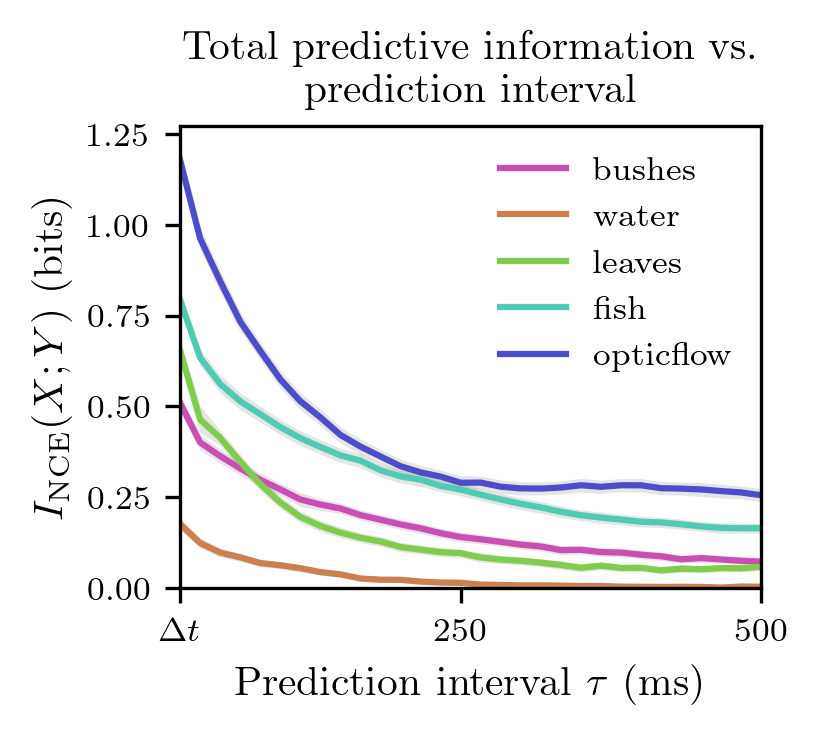

In [ ]:
alp = 0.1

binsize = 1000 / 60
x = (data[0].V_E_buffer_array + 1) * binsize
dt = 1000 / 60

fig, ax = plt.subplots(figsize=[5*plot_scale,4*plot_scale], dpi=300)

for j, stim in enumerate(stimuli):
    y = average_test[j] / np.log(2)
    yerr = stdevs_test[j] / np.log(2)
    # ax.semilogy(x, y, color=colors[j], label=stim)
    ax.plot(x, y, color=colors[j], label=stim)
    ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)


# ax.axhline(0, color=(0,0,0), linestyle='--')
ax.set_xlabel(r'Prediction interval $\tau$ (ms)')
ax.set_ylabel('$I_{\mathrm{NCE}}(X;Y)$ (bits)')
ax.set_xlim(x[0],x[-1])
ax.set_ylim(0)
ax.set_xticks([dt, 250, 500]);
ax.set_xticklabels([r"$\Delta t$",250,500]);
ax.set_title("Total predictive information vs. \n prediction interval")
# ax[0].legend(handles=lines_right)

# plt.savefig('./plots/I vs tau.png', dpi=3000)

In [10]:
data_shuffle[0].V_E_buffer_array

[0, 14, 29]

In [11]:
stdevs_shuffle

[array([0.00388633, 0.00384893, 0.00347304]),
 array([0.00196537, 0.00227167, 0.00261337]),
 array([0.00422358, 0.0034459 , 0.00395645]),
 array([0.00364345, 0.00290151, 0.0029163 ]),
 array([0.00453384, 0.00453117, 0.00440485])]

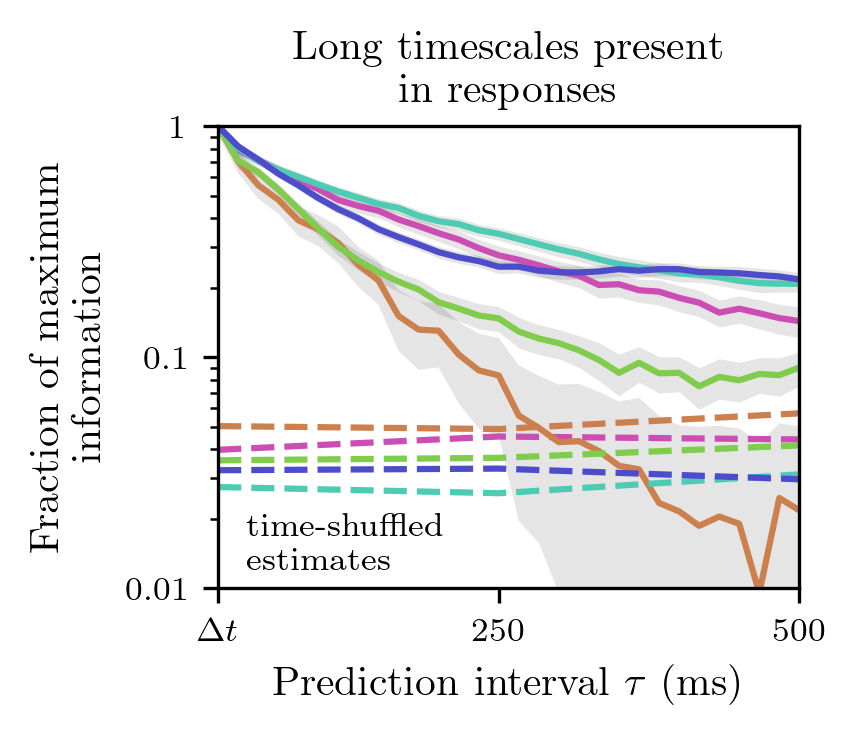

In [ ]:
alp = 0.1

binsize = 1000 / 60
x = (data[0].V_E_buffer_array + 1) * binsize
x_sh = (np.array(data_shuffle[0].V_E_buffer_array) + 1) * binsize
dt = 1000 / 60

fig, ax = plt.subplots(figsize=[5*plot_scale,4*plot_scale], dpi=300)

for j, stim in enumerate(stimuli):
    curmax = np.max(average_test[j])
    # curmax = 1
    y = average_test[j] / curmax
    yerr = stdevs_test[j] / curmax
    ax.semilogy(x, y, color=colors[j])
    ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
    ax.plot(x_sh, np.sqrt(average_shuffle[j]**2 + 0*stdevs_shuffle[j]**2) / curmax, color=colors[j], linestyle='--')

ax.plot([],[], color=(0.7,0.7,0.7), linestyle='--', label='time shuffle')
ax.set_xlabel(r'Prediction interval $\tau$ (ms)')
ax.set_ylabel('Fraction of maximum\n information')
ax.set_xlim(x[0],x[-1])
ax.set_ylim(1E-2, 1)
# ax.set_ylim(0)
ax.set_xticks([dt, 250, 500]);
ax.set_yticks([1,0.1,0.01])
ax.set_yticklabels([1,0.1,0.01])
ax.set_xticklabels([r"$\Delta t$",250,500]);
ax.set_title("Long timescales present\n  in responses")
ax.text(40, 0.012, 'time-shuffled\n estimates')
    
# plt.savefig('./plots/log I vs tau.png', dpi=3000)